In [40]:
import mne
import matplotlib.pyplot as plt
from pathlib import Path

import pandas as pd

ROOT = Path().resolve().parent

set_file = ROOT / "sub-Rc01" / "ses-2" / "eeg" / "sub-Rc01_ses-2_task-SmartickDataset_run-2_eeg.set"

raw = mne.io.read_raw_eeglab(set_file, preload=True)

print(raw)
print("Channels:", len(raw.ch_names))
print("Sampling frequency:", raw.info["sfreq"])
print("Duration:", raw.times[-1], "seconds")
print("Number of samples:", raw.n_times)
print("Channel names:")
print(raw.ch_names)

<RawEEGLAB | sub-Rc01_ses-2_task-SmartickDataset_run-2_eeg.set, 32 x 47177 (184.3 s), ~11.6 MiB, data loaded>
Channels: 32
Sampling frequency: 256.0
Duration: 184.28125 seconds
Number of samples: 47177
Channel names:
['FP1', 'FP2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'FT10', 'FT9', 'T7', 'FC5', 'C3', 'FC1', 'FC2', 'FC6', 'C4', 'Cz', 'CP1', 'CP5', 'TP9', 'CP2', 'CP6', 'TP10', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'Oz', 'O2']


In [32]:
data = raw.get_data()

print("Data shape:", data.shape)

Data shape: (32, 46080)


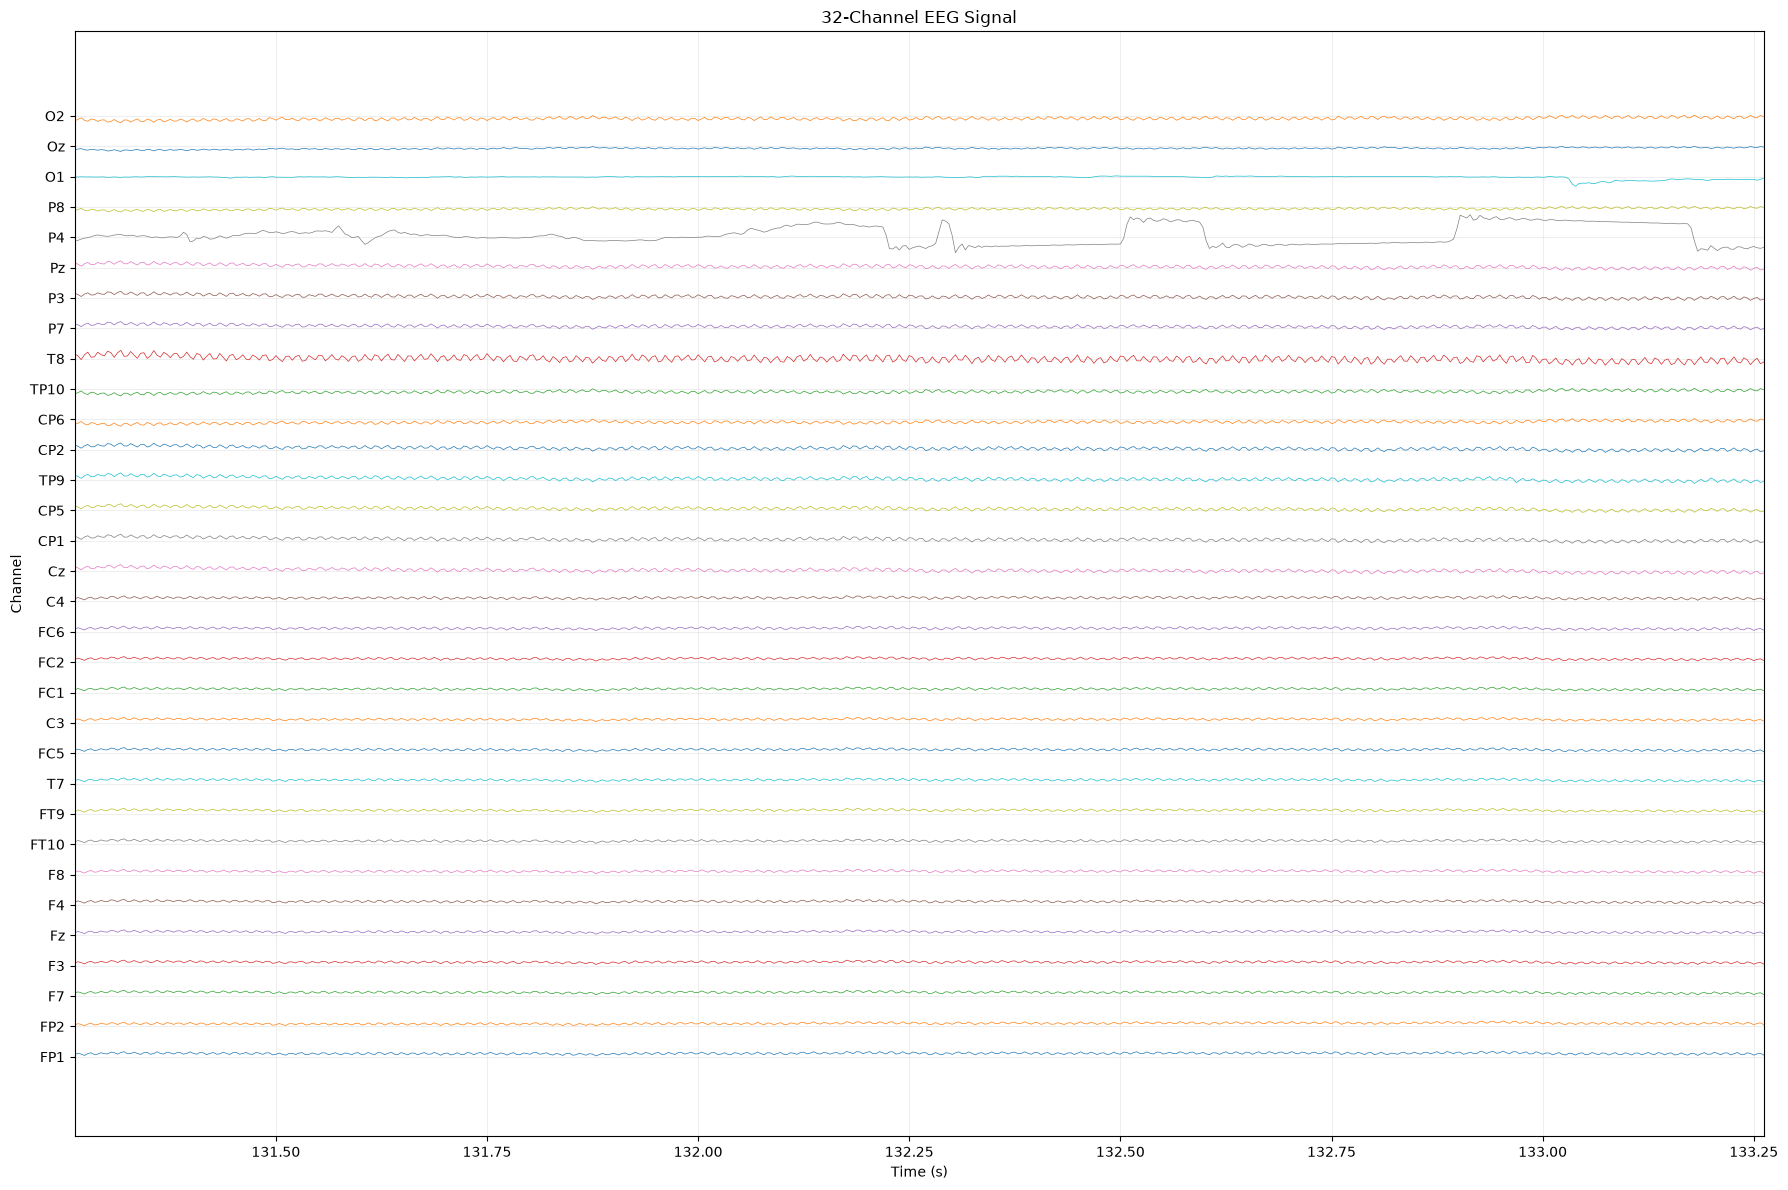

In [39]:
import numpy as np
import matplotlib.pyplot as plt

data = raw.get_data()
times = raw.times

event_time = 131.2617188
end_time = event_time + 2

plt.figure(figsize=(18, 12))

spacing = 5

for i in range(data.shape[0]):
    signal = data[i]

    # Normalize each channel
    signal = (signal - np.mean(signal)) / np.std(signal)

    plt.plot(
        times,
        signal + i * spacing,
        linewidth=0.5
    )

plt.xlabel("Time (s)")
plt.ylabel("Channel")
plt.title("32-Channel EEG Signal")

plt.yticks(
    np.arange(0, data.shape[0] * spacing, spacing),
    raw.ch_names
)

plt.xlim(event_time, end_time)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [4]:
import numpy as np

print("========== EEG RECORDING SUMMARY ==========")

print("Number of channels :", raw.info["nchan"])
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Number of samples :", raw.n_times)
print("Duration          :", raw.times[-1], "seconds")
print("Recording type  :", len(raw.events) if hasattr(raw, "events") else "Continuous EEG")
print("Data shape        :", data.shape)

print("\nChannel names:")
for i, ch in enumerate(raw.ch_names, start=1):
    print(f"{i:2d}. {ch}")

========== EEG RECORDING SUMMARY ==========
Number of channels : 32
Sampling frequency: 256.0 Hz
Number of samples : 57439
Duration          : 224.3671875 seconds
Recording type  : Continuous EEG
Data shape        : (32, 57439)

Channel names:
 1. FP1
 2. FP2
 3. F7
 4. F3
 5. Fz
 6. F4
 7. F8
 8. FT10
 9. FT9
10. T7
11. FC5
12. C3
13. FC1
14. FC2
15. FC6
16. C4
17. Cz
18. CP1
19. CP5
20. TP9
21. CP2
22. CP6
23. TP10
24. T8
25. P7
26. P3
27. Pz
28. P4
29. P8
30. O1
31. Oz
32. O2


In [5]:
sampling_rate = raw.info["sfreq"]
num_samples = raw.n_times

calculated_duration = num_samples / sampling_rate

print("========== DURATION CHECK ==========")
print(f"Samples           : {num_samples}")
print(f"Sampling rate     : {sampling_rate} Hz")
print(f"Calculated        : {calculated_duration:.6f} seconds")
print(f"MNE reported      : {raw.times[-1]:.6f} seconds")

difference = abs(calculated_duration - raw.times[-1])

print(f"Difference        : {difference:.10f} seconds")

if difference < 0.01:
    print("✓ Duration is internally consistent.")
else:
    print("⚠ Duration discrepancy detected.")

========== DURATION CHECK ==========
Samples           : 57439
Sampling rate     : 256.0 Hz
Calculated        : 224.371094 seconds
MNE reported      : 224.367188 seconds
Difference        : 0.0039062500 seconds
✓ Duration is internally consistent.


In [6]:
print("========== DATA QUALITY CHECK ==========")

nan_count = np.isnan(data).sum()
inf_count = np.isinf(data).sum()
zero_count = np.sum(data == 0)

print("NaN values :", nan_count)
print("Inf values :", inf_count)
print("Zero values:", zero_count)

if nan_count == 0:
    print("✓ No NaN values detected.")
else:
    print("⚠ NaN values detected.")

if inf_count == 0:
    print("✓ No infinite values detected.")
else:
    print("⚠ Infinite values detected.")

========== DATA QUALITY CHECK ==========
NaN values : 0
Inf values : 0
Zero values: 0
✓ No NaN values detected.
✓ No infinite values detected.


In [7]:
# Basic amplitude screening

peak_amplitude = np.max(np.abs(data), axis=1) * 1e6

artifact_screen = pd.DataFrame({
    "Channel": raw.ch_names,
    "Peak Amplitude (µV)": peak_amplitude
})

artifact_screen.sort_values(
    "Peak Amplitude (µV)",
    ascending=False
).round(2)

,Channel,Peak Amplitude (µV)
22,TP10,247058.75
7,FT10,189304.14
29,O1,76102.89
5,F4,8386.72
2,F7,8352.59
4,Fz,8349.56
6,F8,8348.68
9,T7,8344.32
0,FP1,8340.91
3,F3,8335.73


In [8]:
import pandas as pd

channel_stats = pd.DataFrame({
    "Channel": raw.ch_names,
    "Min (µV)": np.min(data, axis=1) * 1e6,
    "Max (µV)": np.max(data, axis=1) * 1e6,
    "Mean (µV)": np.mean(data, axis=1) * 1e6,
    "Std (µV)": np.std(data, axis=1) * 1e6,
    "RMS (µV)": np.sqrt(np.mean(data**2, axis=1)) * 1e6
})

channel_stats.round(3)

,Channel,Min (µV),Max (µV),Mean (µV),Std (µV),RMS (µV)
0,FP1,-8340.910,3829.022,-0.063,920.880,920.880
1,FP2,-8323.297,3836.714,-0.070,921.571,921.571
2,F7,-8352.586,3833.331,0.029,922.635,922.635
3,F3,-8335.734,3937.331,0.037,928.444,928.444
4,Fz,-8349.556,3875.146,0.015,923.917,923.917
5,F4,-8386.723,3829.631,0.018,924.541,924.541
6,F8,-8348.681,3851.159,-0.009,924.373,924.373
7,FT10,-189304.141,180487.203,0.325,28578.417,28578.417
8,FT9,-8323.193,3856.388,0.032,920.029,920.029
9,T7,-8344.320,3884.636,0.031,923.563,923.563


In [9]:
channel_std = np.std(data, axis=1)

flat_threshold = 1e-12

flat_channels = [
    raw.ch_names[i]
    for i, std in enumerate(channel_std)
    if std < flat_threshold
]

print("========== FLAT CHANNEL CHECK ==========")

if flat_channels:
    print("Potentially flat channels:")
    for ch in flat_channels:
        print(" -", ch)
else:
    print("✓ No completely flat channels detected.")

========== FLAT CHANNEL CHECK ==========
✓ No completely flat channels detected.


In [10]:
idx = np.searchsorted(raw.times, raw.times[-1]/2)

half_time = raw.times[-1] / 2
full_time = raw.times[-1]

half = half_time.round(0)
full = full_time.round(0)

before = data[:, :idx]
after = data[:, idx:]

comparison = pd.DataFrame({
    "Channel": raw.ch_names,
    f"STD 0–{half}s (µV)": np.std(before, axis=1) * 1e6,
    f"STD {half}–{full}s (µV)": np.std(after, axis=1) * 1e6
})

comparison["Ratio"] = (
    comparison[f"STD {half}–{full}s (µV)"] /
    comparison[f"STD 0–{half}s (µV)"]
)

comparison.round(3)

,Channel,STD 0–112.0s (µV),STD 112.0–224.0s (µV),Ratio
0,FP1,480.522,1210.420,2.519
1,FP2,480.411,1211.515,2.522
2,F7,481.855,1212.561,2.516
3,F3,483.856,1220.606,2.523
4,Fz,482.331,1214.324,2.518
5,F4,482.929,1215.035,2.516
6,F8,482.660,1214.886,2.517
7,FT10,15209.949,37444.471,2.462
8,FT9,479.897,1209.373,2.520
9,T7,481.413,1214.149,2.522


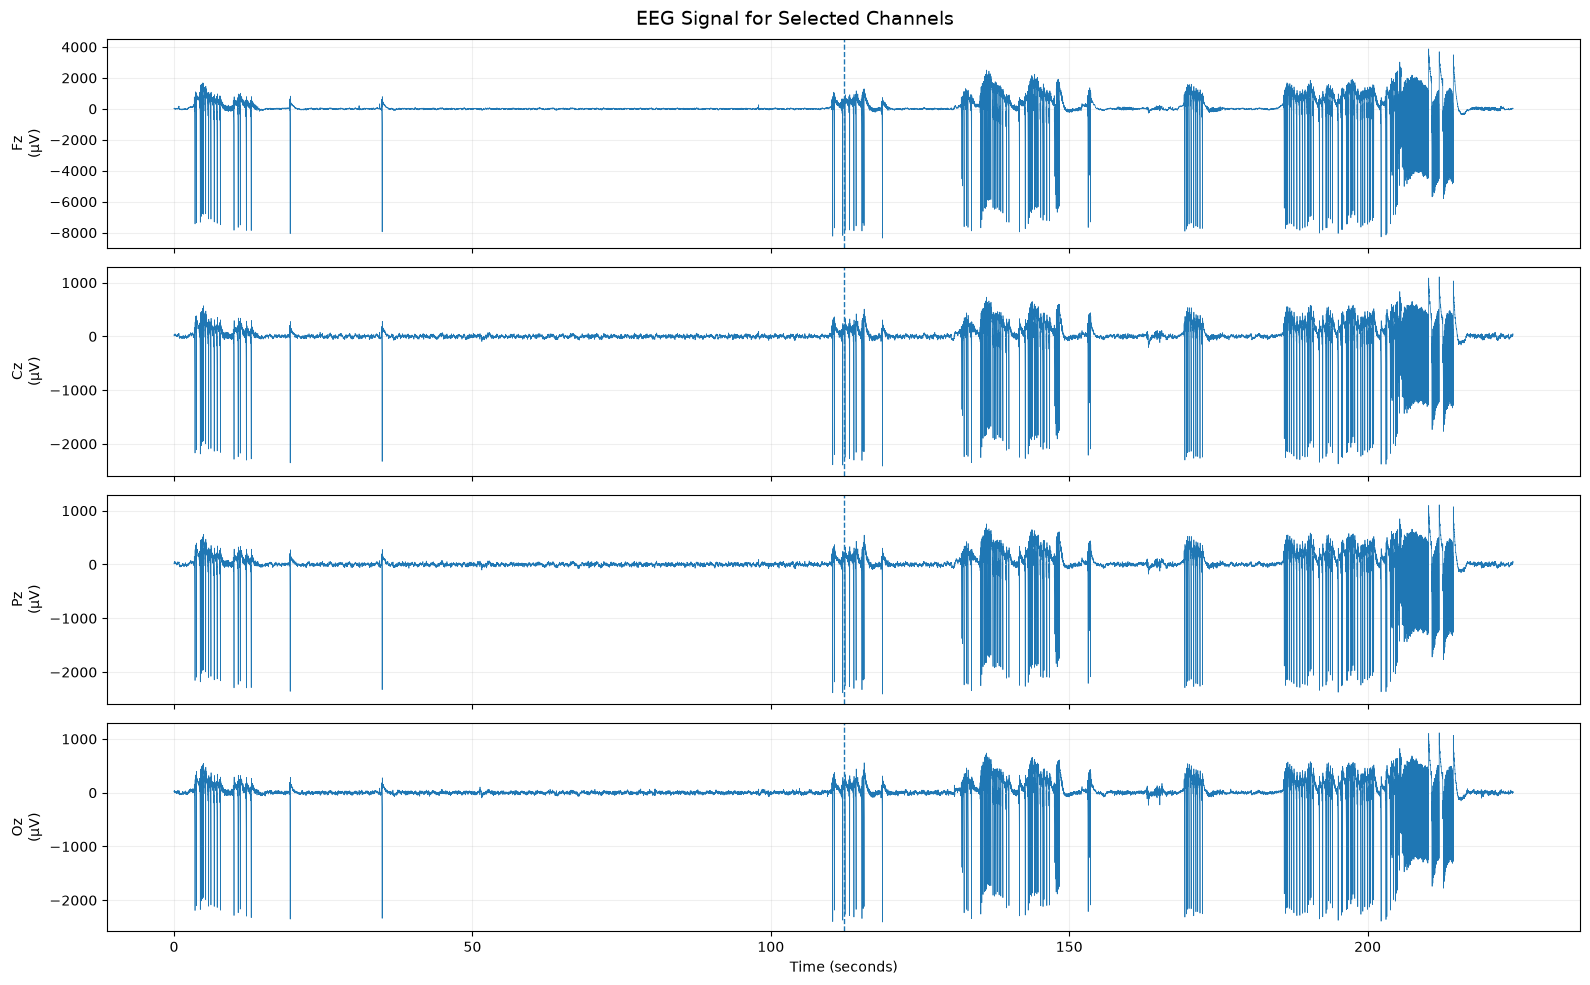

In [11]:
channels_to_plot = ["Fz", "Cz", "Pz", "Oz"]

fig, axes = plt.subplots(
    len(channels_to_plot),
    1,
    figsize=(16, 10),
    sharex=True
)

for ax, ch in zip(axes, channels_to_plot):

    idx = raw.ch_names.index(ch)

    ax.plot(
        raw.times,
        data[idx] * 1e6,
        linewidth=0.5
    )

    ax.axvline(
        raw.times[-1]/2,
        linestyle="--",
        linewidth=1
    )

    ax.set_ylabel(f"{ch}\n(µV)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle(
    "EEG Signal for Selected Channels",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [23]:
# EEG preprocessing

raw_clean = raw.copy()

# Band-pass filtering
raw_clean.filter(
    l_freq=0.5,
    h_freq=50.0,
    fir_design="firwin"
)

# Notch filter for power-line interference
raw_clean.notch_filter(freqs=50)

print("Preprocessing completed.")
print("High-pass filter : 0.5 Hz")
print("Low-pass filter  : 50 Hz")
print("Notch filter     : 50 Hz")

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 50 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 50.00 Hz
- Upper transition bandwidth: 12.50 Hz (-6 dB cutoff frequency: 56.25 Hz)
- Filter length: 1691 samples (6.605 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband e

Effective window size : 8.000 (s)
Plotting power spectral density (dB=True).


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_97369/3912861632.py:5: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  ).plot(


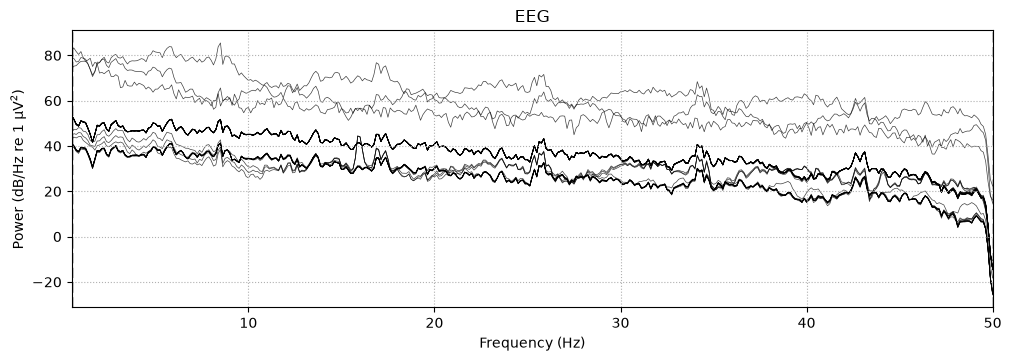

In [34]:
raw_clean.compute_psd(
    fmin=0.5,
    fmax=50,
    n_fft=2048
).plot(
    average=False,
    picks="data"
)

plt.show()

Effective window size : 8.000 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


/var/folders/tj/grr23q4s2332hjy11pnwmt0c0000gn/T/ipykernel_97369/2935134755.py:7: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  ).plot(


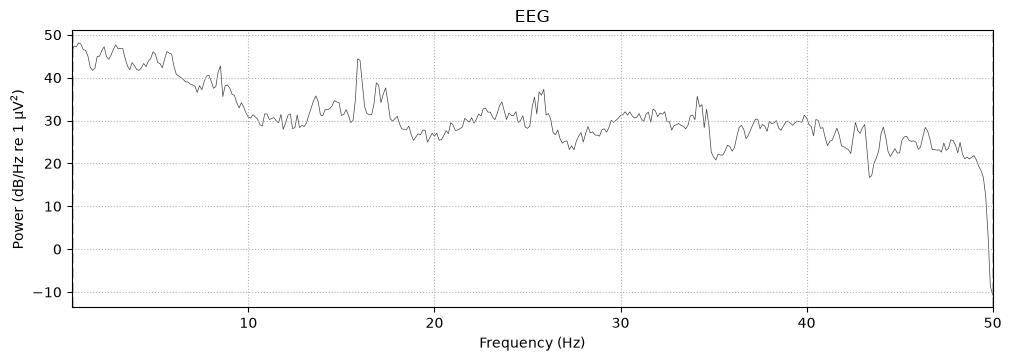

In [35]:
selected_channels = ["O2"]

raw_clean.compute_psd(
    fmin=0.5,
    fmax=50,
    n_fft=2048
).plot(
    picks=selected_channels,
    average=False
)

plt.show()

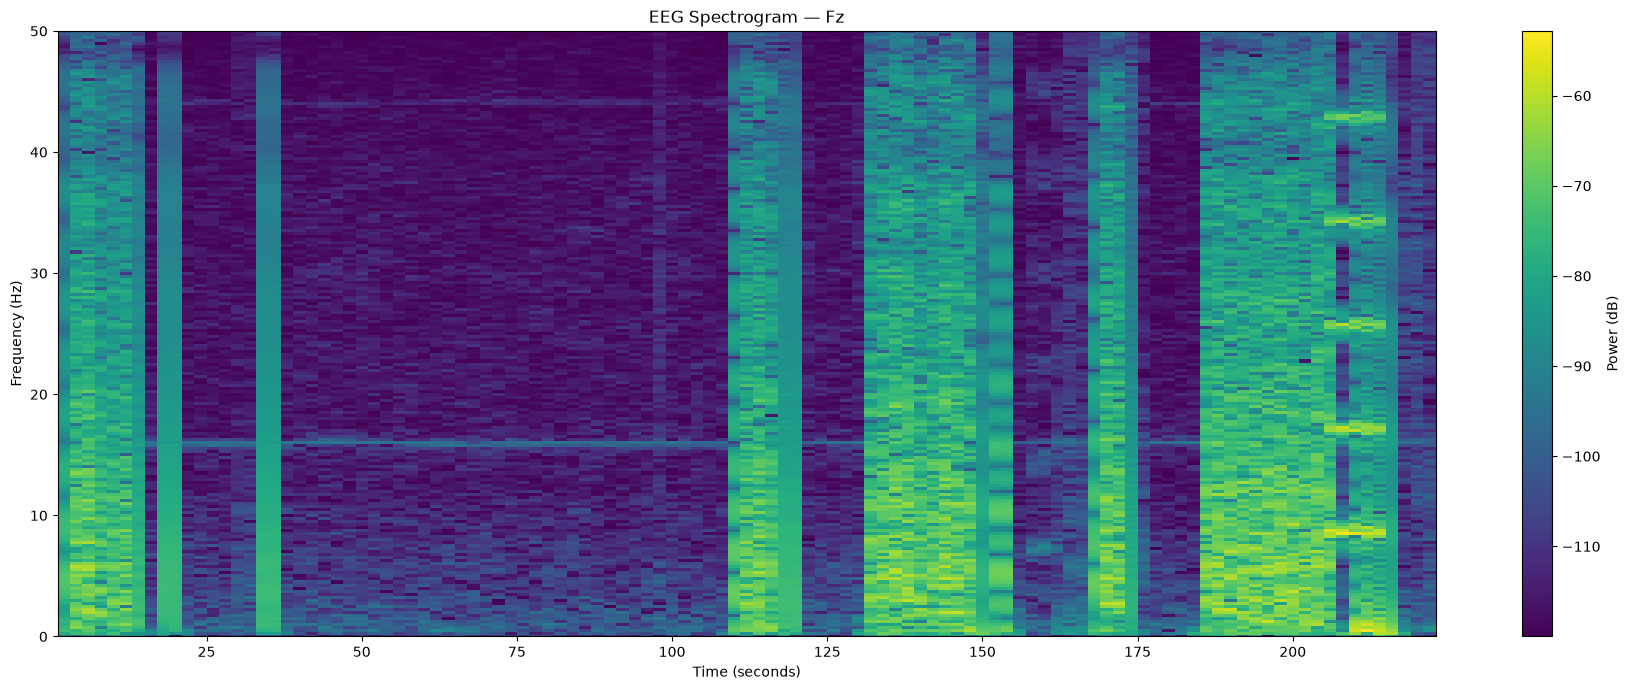

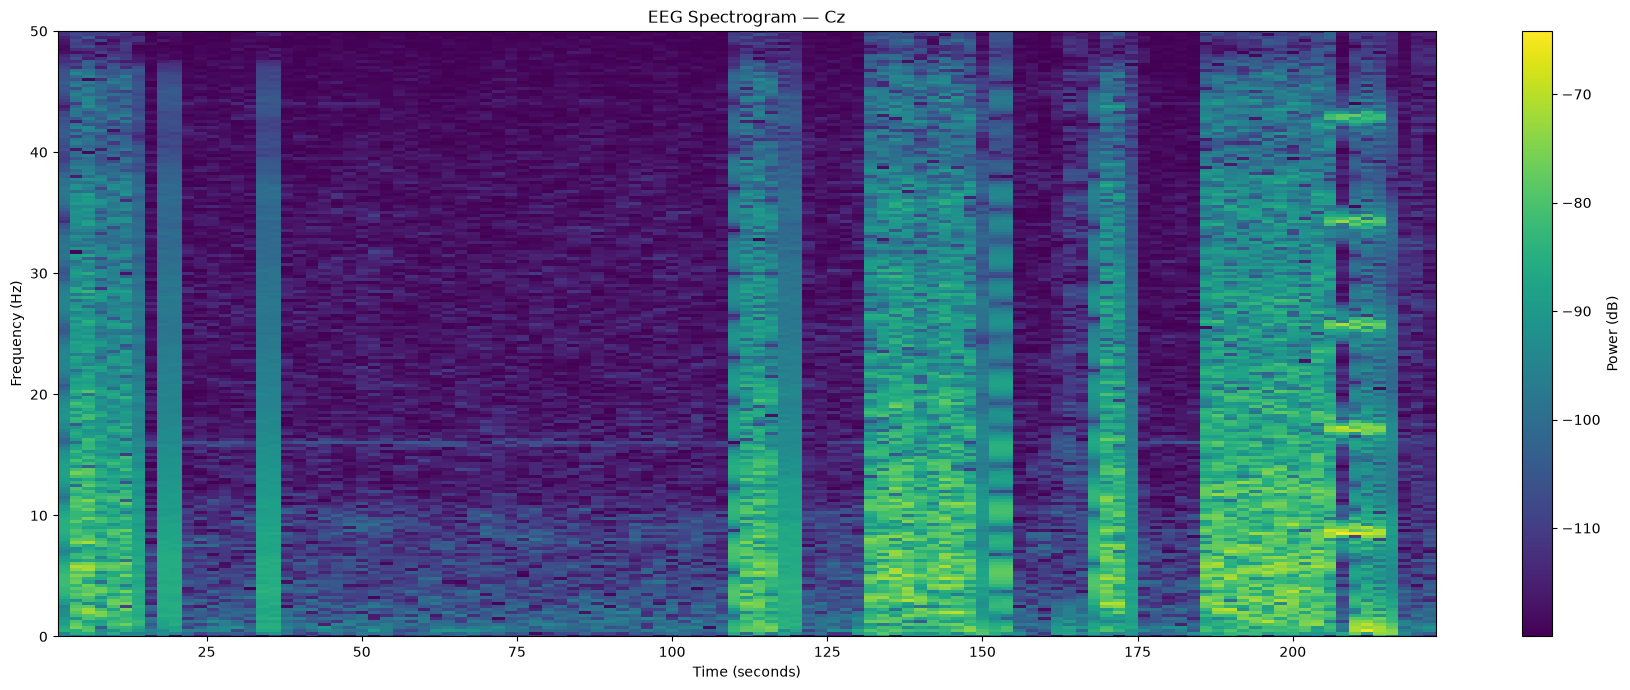

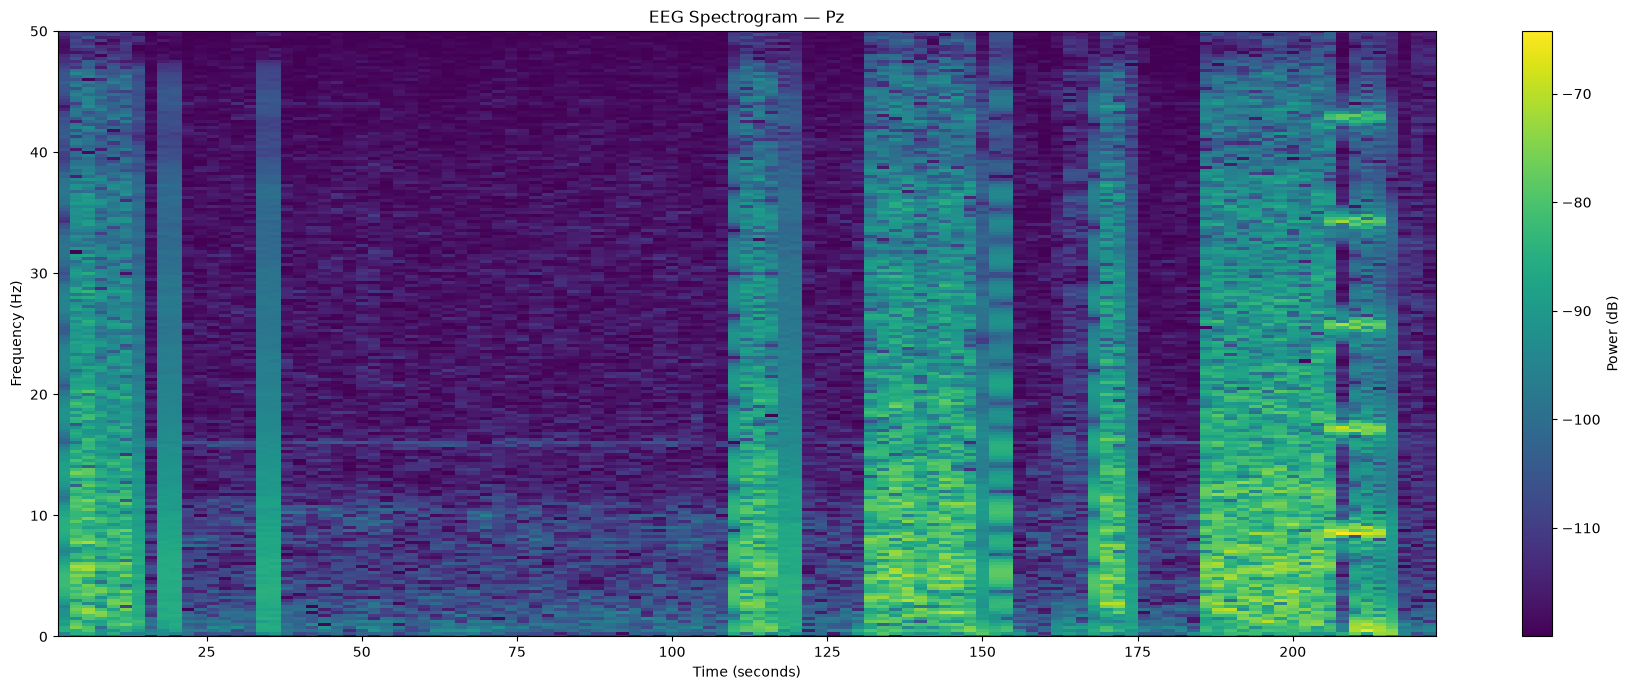

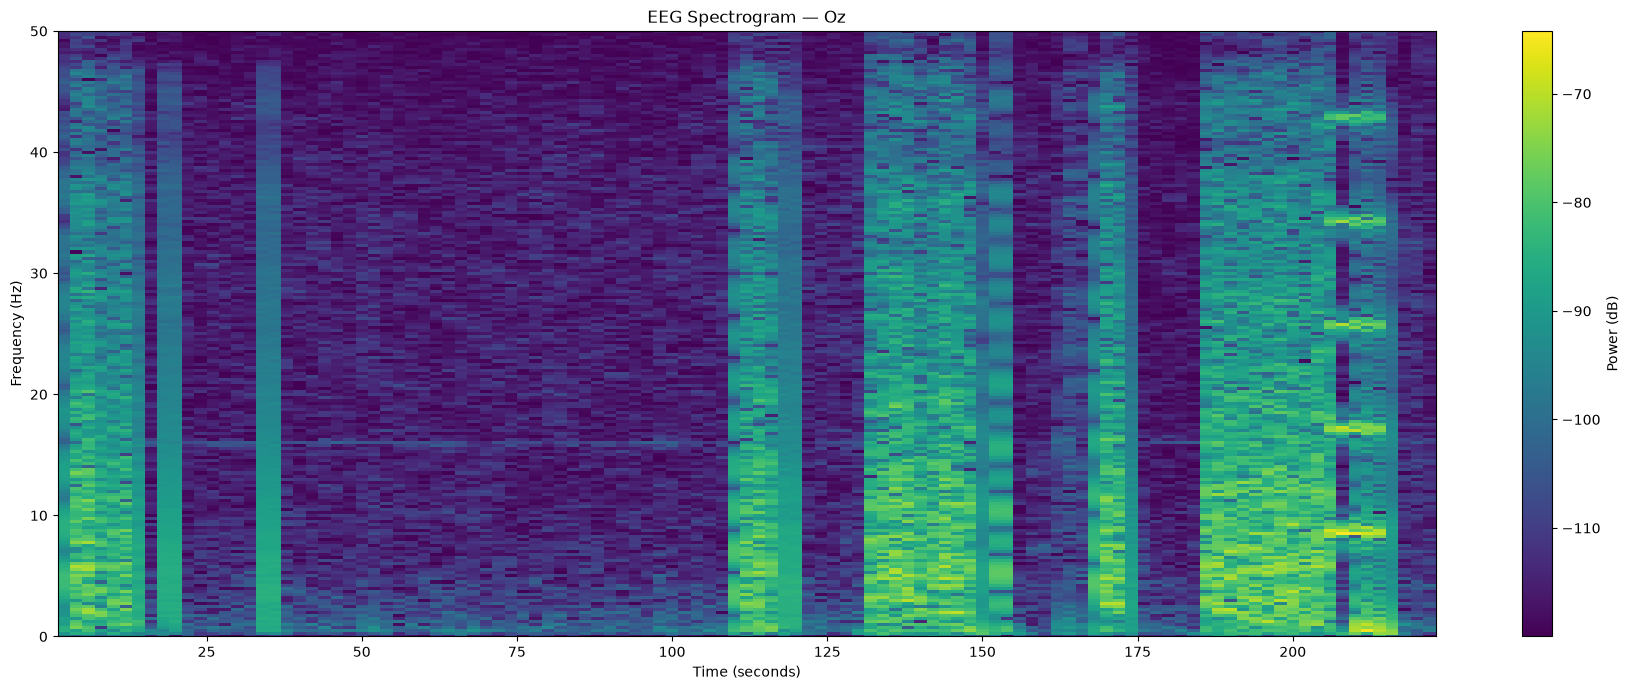

In [15]:
from scipy import signal

selected_channels = ["Fz", "Cz", "Pz", "Oz"]

for ch in selected_channels:
    idx = raw_clean.ch_names.index(ch)

    eeg_signal = data[idx]

    freqs, times_spec, Sxx = signal.spectrogram(
        eeg_signal,
        fs=raw_clean.info["sfreq"],
        nperseg=1024,
        noverlap=512
    )

    mask = freqs <= 50

    plt.figure(figsize=(18, 7))

    plt.pcolormesh(
        times_spec,
        freqs[mask],
        10 * np.log10(Sxx[mask] + 1e-12),
        shading="auto"
    )

    plt.xlabel("Time (seconds)")
    plt.ylabel("Frequency (Hz)")
    plt.title(f"EEG Spectrogram — {ch}")

    plt.ylim(0, 50)

    plt.colorbar(label="Power (dB)")

    plt.tight_layout()
    plt.show()

In [16]:
for ch in ["Fz", "Cz", "Pz", "Oz"]:

    idx = raw_clean.ch_names.index(ch)

    signal_uv = data[idx] * 1e6

    max_idx = np.argmax(np.abs(signal_uv))

    print(
        f"{ch}: "
        f"time={raw_clean.times[max_idx]:.3f}s, "
        f"value={signal_uv[max_idx]:.2f} µV"
    )

Fz: time=118.707s, value=-8349.56 µV
Cz: time=118.707s, value=-2413.56 µV
Pz: time=118.707s, value=-2408.27 µV
Oz: time=118.707s, value=-2405.02 µV


Using matplotlib as 2D backend.


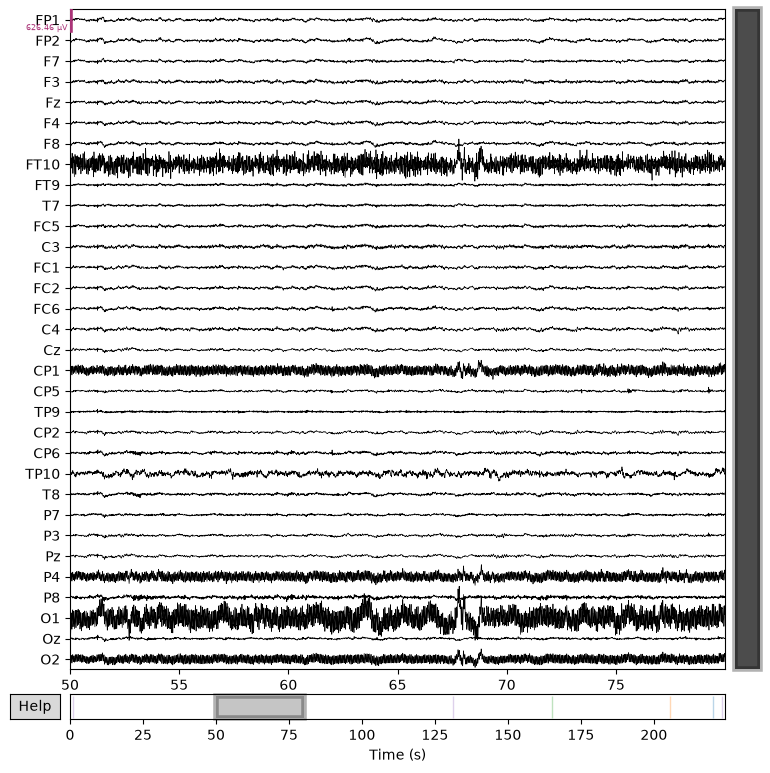

In [17]:
fig = raw_clean.plot(
    start=50,
    duration=30,
    n_channels=32,
    scalings="auto"
)

In [18]:
print("========== ANNOTATIONS ==========")
print(raw.annotations)

events, event_id = mne.events_from_annotations(raw)

print("\nEvents shape:", events.shape)
print("Event IDs:", event_id)

if len(events) > 0:
    print("\nFirst events:")
    print(events[:20])
else:
    print("No annotation-based events found.")

========== ANNOTATIONS ==========
<Annotations | 6 segments: 33026 (1), 33027 (1), 33028 (1), condition 4 (3)>
Used Annotations descriptions: ['33026', '33027', '33028', 'condition 4']

Events shape: (6, 3)
Event IDs: {'33026': 1, '33027': 2, '33028': 3, 'condition 4': 4}

First events:
[[  255     0     4]
 [33603     0     4]
 [42278     0     3]
 [52579     0     2]
 [56405     0     1]
 [57181     0     4]]
